Cell 1 — Imports and paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_log_error

BASE_DIR = Path(r"C:\Users\NickK\OneDrive\Υπολογιστής\github\kaggle_store_sales_forecasting")
ADVANCED_DIR = BASE_DIR / "data" / "advanced"

Cell 2 — Load expanded dataset

In [2]:
train = pd.read_csv(ADVANCED_DIR / "train_expanded_features.csv")
train["date"] = pd.to_datetime(train["date"])

print(train.shape)
train.head()

(3000888, 50)


,id,date,store_nbr,family,sales,onpromotion,year,month,day,quarter,...,rolling_median_28,rolling_min_28,rolling_max_28,rolling_std_7,rolling_std_14,rolling_std_28,rolling_std_56,promo_rolling_mean_7,promo_rolling_mean_14,promo_rolling_mean_28
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,2013,1,2,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,2013,1,3,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,2013,1,4,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,2013,1,5,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Cell 3 — Feature list

In [3]:
target = "sales"

features = [
    "store_nbr", "family", "onpromotion",
    "year", "month", "day", "quarter", "week", "day_of_week", "is_weekend",
    "city", "state", "type", "cluster",
    "dcoilwtico", "is_payday", "is_national_holiday", "earthquake_period",
    
    "sales_lag_1", "sales_lag_2", "sales_lag_3",
    "sales_lag_7", "sales_lag_14", "sales_lag_21", "sales_lag_28", "sales_lag_56",
    
    "rolling_mean_3", "rolling_mean_7", "rolling_mean_14", "rolling_mean_28", "rolling_mean_56",
    
    "rolling_median_7", "rolling_median_14", "rolling_median_28",
    "rolling_min_7", "rolling_min_14", "rolling_min_28",
    "rolling_max_7", "rolling_max_14", "rolling_max_28",
    
    "rolling_std_7", "rolling_std_14", "rolling_std_28", "rolling_std_56",
    
    "promo_rolling_mean_7", "promo_rolling_mean_14", "promo_rolling_mean_28"
]

X = train[features]
y = np.log1p(train[target])

print(X.shape)
print(y.shape)

(3000888, 47)
(3000888,)


Cell 4 — One-hot encoding

In [4]:
X = pd.get_dummies(X, drop_first=True)

print(X.shape)

(3000888, 115)


Cell 5 — Time-based validation split

In [5]:
split_date = "2017-01-01"

train_mask = train["date"] < split_date
valid_mask = train["date"] >= split_date

X_train = X.loc[train_mask]
X_valid = X.loc[valid_mask]

y_train = y.loc[train_mask]
y_valid_original = train.loc[valid_mask, target]

print(X_train.shape)
print(X_valid.shape)
print(y_train.shape)
print(y_valid_original.shape)

(2596374, 115)
(404514, 115)
(2596374,)
(404514,)


Cell 6 — Train XGBoost model

In [6]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("Model trained.")

Model trained.


Cell 7 — Validation RMSLE

In [7]:
valid_log_preds = xgb_model.predict(X_valid)

valid_preds = np.expm1(valid_log_preds)
valid_preds = np.maximum(valid_preds, 0)

rmsle = np.sqrt(
    mean_squared_log_error(
        y_valid_original,
        valid_preds
    )
)

print("Validation RMSLE:", rmsle)

Validation RMSLE: 0.43251439453266444


Cell 8 — Feature importance

In [8]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance.head(30)

,feature,importance
23,rolling_mean_7,0.418639
22,rolling_mean_3,0.299108
27,rolling_median_7,0.134032
14,sales_lag_1,0.075252
17,sales_lag_7,0.020653
18,sales_lag_14,0.006828
64,"family_LIQUOR,WINE,BEER",0.005478
60,family_HOME CARE,0.002086
24,rolling_mean_14,0.002078
3,month,0.001979


Cell 9 — Plot top features

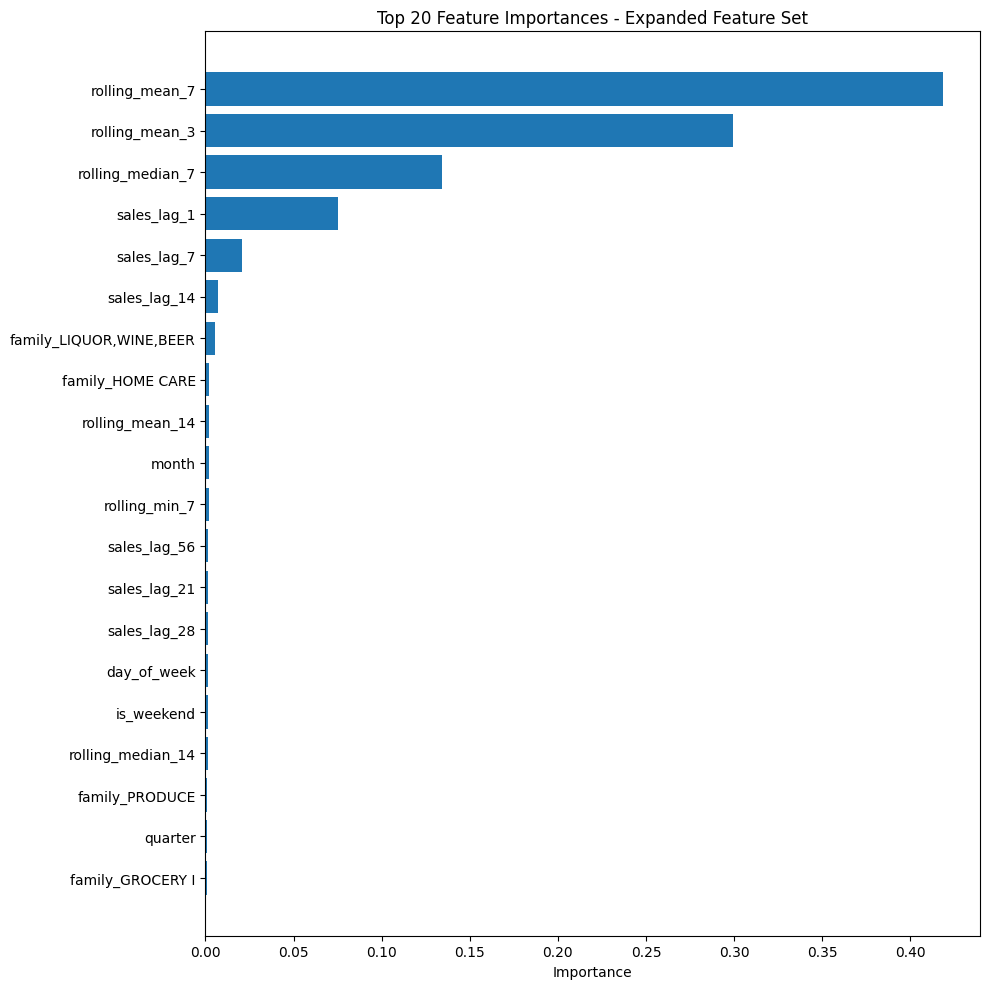

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

plt.barh(
    feature_importance.head(20)["feature"][::-1],
    feature_importance.head(20)["importance"][::-1]
)

plt.title("Top 20 Feature Importances - Expanded Feature Set")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()